In [1]:
import pandas as pd

In [2]:
viirs_df = pd.read_csv('viirs_20.csv')

In [3]:
viirs_df.head()

,state,longitude,latitude,light_intensity,year,observations
0,bahia,-46.6,-11.295833,0.340000,2020,3
1,bahia,-46.6,-11.291667,0.240000,2020,3
2,bahia,-46.6,-11.287500,0.303333,2020,3
3,bahia,-46.6,-11.283333,0.296667,2020,3
4,bahia,-46.6,-11.279167,0.290000,2020,2


In [4]:
viirs_df.shape

(4219479, 6)

In [5]:
viirs_df.columns

Index(['state', 'longitude', 'latitude', 'light_intensity', 'year',
       'observations'],
      dtype='object')

In [6]:
viirs_df.dtypes

state               object
longitude          float64
latitude           float64
light_intensity    float64
year                 int64
observations         int64
dtype: object

In [7]:
viirs_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4219479 entries, 0 to 4219478
Data columns (total 6 columns):
 #   Column           Dtype  
---  ------           -----  
 0   state            object 
 1   longitude        float64
 2   latitude         float64
 3   light_intensity  float64
 4   year             int64  
 5   observations     int64  
dtypes: float64(3), int64(2), object(1)
memory usage: 193.2+ MB


In [8]:
viirs_df.describe()

,longitude,latitude,light_intensity,year,observations
count,4.219479e+06,4.219479e+06,4.219479e+06,4219479.0,4.219479e+06
mean,-4.386095e+01,-1.596449e+01,9.672595e-01,2020.0,2.913716e+00
std,3.819068e+00,5.001738e+00,5.649924e+00,0.0,2.817345e-01
min,-5.313333e+01,-2.533750e+01,5.666667e-02,2020.0,1.000000e+00
25%,-4.712917e+01,-2.162083e+01,2.600000e-01,2020.0,3.000000e+00
50%,-4.317083e+01,-1.401667e+01,3.050000e-01,2020.0,3.000000e+00
75%,-4.057500e+01,-1.173333e+01,3.966667e-01,2020.0,3.000000e+00
max,-3.735417e+01,-8.570833e+00,2.819420e+03,2020.0,3.000000e+00


In [9]:
viirs_df.isnull().sum()

state              0
longitude          0
latitude           0
light_intensity    0
year               0
observations       0
dtype: int64

In [10]:
viirs_df.isna().sum()

state              0
longitude          0
latitude           0
light_intensity    0
year               0
observations       0
dtype: int64

In [11]:
viirs_df.duplicated().sum()

0

In [12]:
# do not run this, no duplications found

# duplicated_rows = viirs_df[viirs_df.duplicated(keep=False)]

# sample_of_duplicates = duplicated_rows.sample(n=10, random_state=42)
# print(sample_of_duplicates)

array([[<Axes: title={'center': 'longitude'}>,
        <Axes: title={'center': 'latitude'}>],
       [<Axes: title={'center': 'light_intensity'}>,
        <Axes: title={'center': 'year'}>],
       [<Axes: title={'center': 'observations'}>, <Axes: >]], dtype=object)

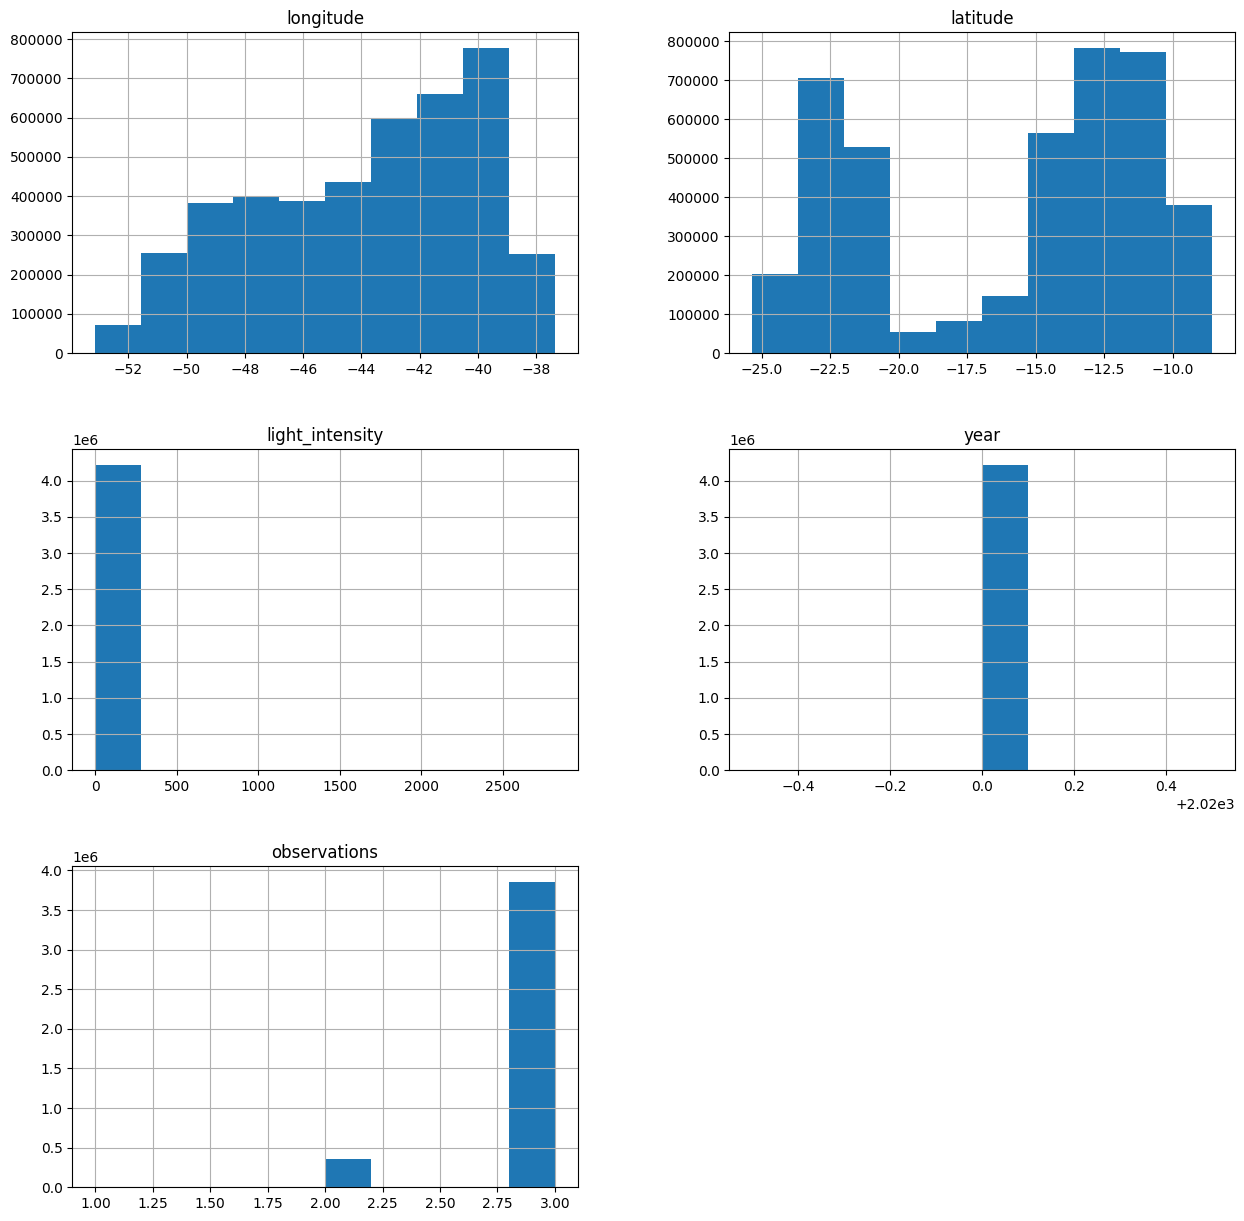

In [13]:
viirs_df.hist(figsize=(15,15))

In [14]:
zero_count = (viirs_df['light_intensity'] == 0).sum()

print(f"Number of zeroes in the column 'light_intensity': {zero_count}")

Number of zeroes in the column 'light_intensity': 0


In [15]:
neg_count = (viirs_df['light_intensity'] < 0).sum()

print(f"Number of negative values in the column 'light_intensity': {neg_count}")

Number of negative values in the column 'light_intensity': 0


In [16]:
viirs_cleaned_df = viirs_df[viirs_df['light_intensity'] > 0]

viirs_cleaned_df.to_csv('viirs_20_cleaned.csv', index=False)

print("Cleaned dataset saved as 'viirs_20_cleaned.csv'")

Cleaned dataset saved as 'viirs_20_cleaned.csv'


C:\Users\PC\AppData\Local\Temp\ipykernel_14668\870355554.py:9: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(


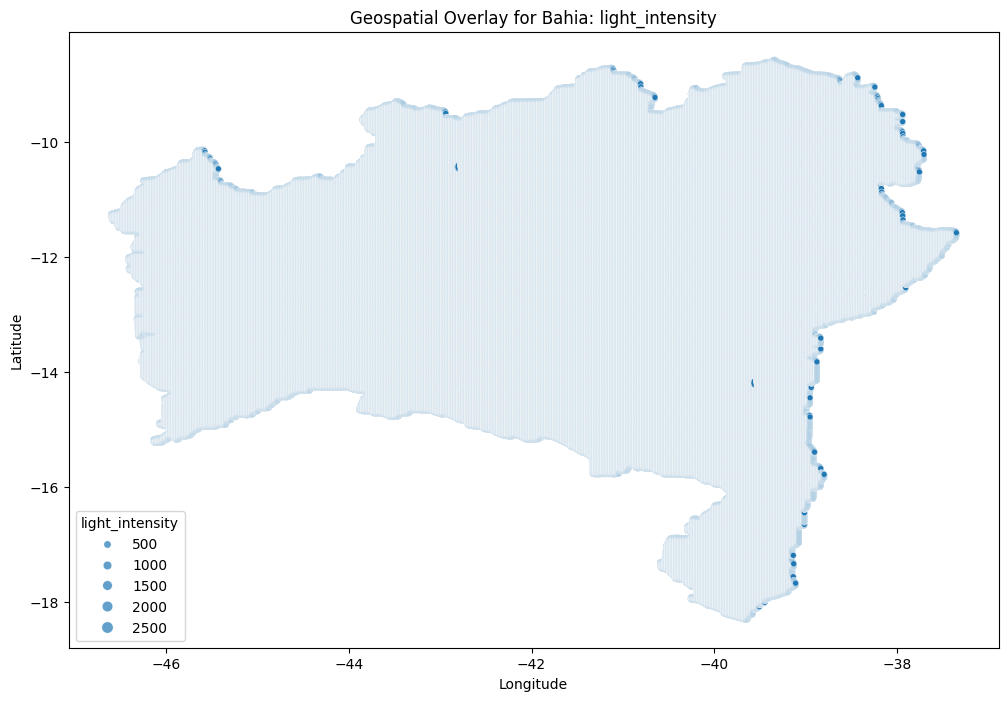

C:\Users\PC\AppData\Local\Temp\ipykernel_14668\870355554.py:9: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(


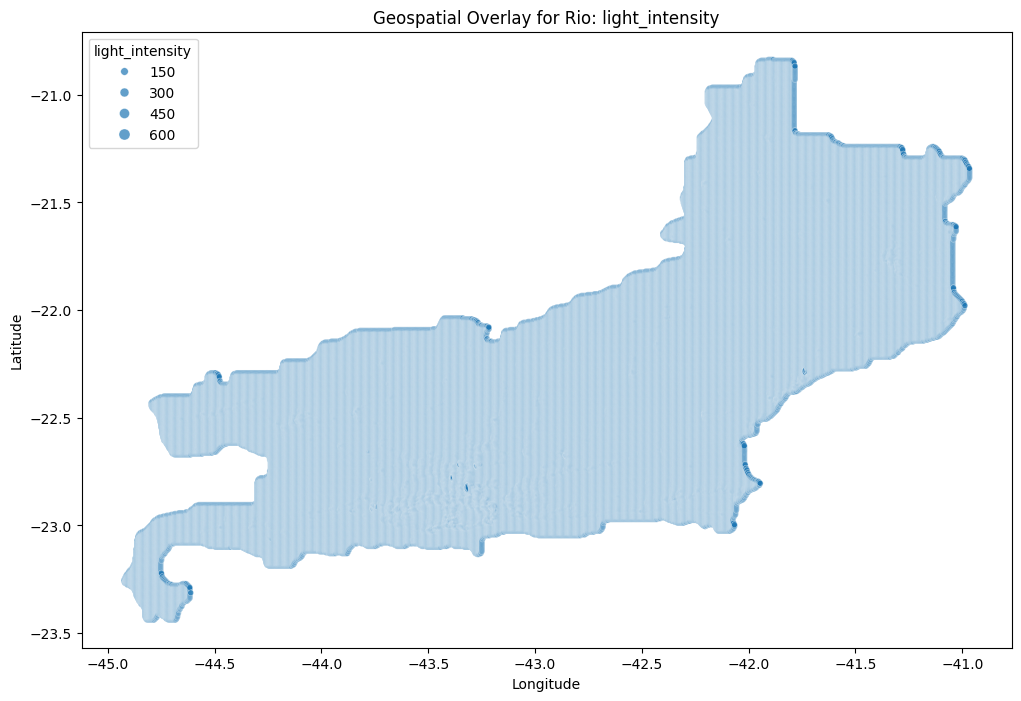

C:\Users\PC\AppData\Local\Temp\ipykernel_14668\870355554.py:9: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(


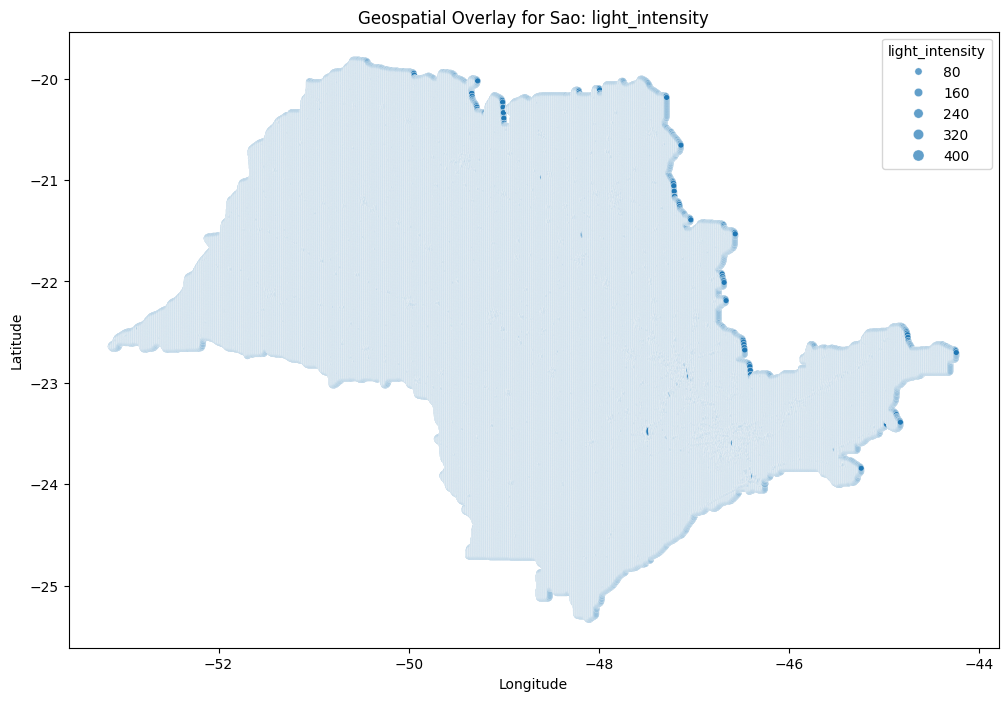

In [17]:
from matplotlib import pyplot as plt
import seaborn as sns

# Function to create individual plots for each city

def create_city_plot(city):
    city_df = viirs_cleaned_df[viirs_cleaned_df['state'] == city]
    plt.figure(figsize=(12, 8))
    sns.scatterplot(
        data=city_df,
        x='longitude',
        y='latitude',
        size='light_intensity',
        # hue='avg_d_kbps',
        palette='viridis',
        alpha=0.7
    )
    plt.title(f"Geospatial Overlay for {city.capitalize()}: light_intensity")
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    # plt.legend(title="Average Download Speeds (kbps)")
    plt.show()

# Generate plots for each city
for city in viirs_cleaned_df['state'].unique():
    create_city_plot(city)

In [18]:
# # Step 1: Drop the 'state' column and check for duplicates
# duplicated_mask = viirs_cleaned_df.drop(columns=['state']).duplicated()

# # Step 2: Get the duplicated rows
# duplicated_rows = viirs_cleaned_df[duplicated_mask]

# # Step 3: Output the result
# print("Duplicated Rows (Ignoring 'state'):")
# print(duplicated_rows)

# # Step 4: Count of duplicates
# print(f"Number of duplicates: {duplicated_rows.shape[0]}")

In [25]:
# viirs_cleaned_df.duplicated().sum()

In [26]:
# viirs_cleaned_df.info()

In [21]:
# # # approach 1
# # total_radiance = viirs_cleaned_df['light_intensity'].sum()
# # viirs_cleaned_df['radiance_pct_change'] = (viirs_cleaned_df['light_intensity'] / total_radiance) * 100

# # viirs_cleaned_df = viirs_cleaned_df[viirs_cleaned_df['radiance_pct_change'] > 0]

# # viirs_cleaned_df = viirs_cleaned_df.drop_duplicates()

# # print(viirs_cleaned_df.head())

# # =====================================================================================

# # approach 2
# viirs_cleaned_df['radiance_pct_change'] = viirs_cleaned_df.groupby(['state', 'month'])['light_intensity'].pct_change() * 100

# viirs_cleaned_df = viirs_cleaned_df[viirs_cleaned_df['radiance_pct_change'] > 0]

# viirs_cleaned_df = viirs_cleaned_df.drop_duplicates()

# print(viirs_cleaned_df.head())

# # =====================================================================================

# # # approach 3
# # viirs_cleaned_df['radiance_pct_change'] = viirs_cleaned_df.groupby(['state', 'month'])['light_intensity'].pct_change().fillna(0)

In [22]:
# viirs_cleaned_df['radiance_pct_change'].describe()

In [27]:
# viirs_cleaned_df['light_intensity'].describe()

In [28]:
# viirs_cleaned_df.head()